In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path
import nltk
nltk.download("stopwords")
import spacy  # only needed once


pd.options.display.max_columns = 100

from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to /home/jupyter-
[nltk_data]     vojta/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
nlp_eng = spacy.load("en_core_web_md")
nlp_fra = spacy.load("fr_core_news_md")
nlp_ger = spacy.load("de_core_news_md")

In [4]:
DATA_DIR = next(
    (
        folder / "data/k10plus"
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data" / "k10plus" / "export.json").exists()
    ),
    None,
)
assert DATA_DIR is not None, "data/k10plus/export.json not found above the working directory"
print("DATA_DIR:", DATA_DIR)

DATA_DIR: /home/jupyter-vojta/notebooks/biblical-books/data/k10plus


In [5]:
books = pd.read_parquet(DATA_DIR / "books_full.parquet", dtype_backend="pyarrow")
books["record_id"] = books.record_id.astype("string")  # materialise in one go
print(f"{len(books):,} rows, {len(books.columns)} columns")
books.head(5)

300,542 rows, 43 columns


,record_id,source_url,leader,record_type,bibliographic_level,title,subtitle,full_title,responsibility,publication_statement,date_text,edition,extent,abstract,date_type,first_seen,last_seen,authors,editors,contributors,languages,isbns,issns,dois,publishers,publication_places,subjects,subject_authority_ids,ddc,lcc,other_classifications,series,urls,related_record_ids,notes,matched_queries,name_authority_ids,authority_ids,contributor_types,publication_year,is_textual_monograph,contributor_records,subjects_structured
0,010017054,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=01...,cam a22 c 4500,a,m,Du gibst weiten Raum meinen Schritten,Lebensmut aus der Bibel,Du gibst weiten Raum meinen Schritten: Lebensm...,Walter Strolz,Freiburg im Breisgau [u.a.] Herder 1980,1980,,128 S,,s,2026-11-18T13:19:28.460603+00:00,2026-11-18T13:19:28.460603+00:00,"['Strolz, Walter']",[],"['Strolz, Walter']",['ger'],['3451191326'],[],[],['Herder'],['Freiburg im Breisgau [u.a.]'],['Bibel' 'Betrachtung'],['4006406-2' '4280396-2' '4071867-0'],[],[],['02a sdnb' '1 ssgn' 'BT 2050 rvk (DE-625)rvk/...,[],[],[],[],['subject_bibel'],['124873324'],['124873324' '4006406-2' '4280396-2' '4071867-0'],['aut'],1980,True,"[{'sequence': 1, 'marc_tag': '100', 'is_primar...","[{'sequence': 1, 'marc_tag': '630', 'entity_ty..."
1,010021817,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=01...,cam a22 c 4500,a,m,Mittelpunkt Bibel,Ulrich Fick zum 60. Geburtstag,Mittelpunkt Bibel: Ulrich Fick zum 60. Geburtstag,hrsg. von Siegfried Meurer,Stuttgart Dt. Bibelges. 1983,1983,,"336 S. Ill., Notenbeisp.",,s,2026-11-18T11:21:03.383857+00:00,2026-11-18T13:16:12.965666+00:00,[],[],"['Meurer, Siegfried' 'Fick, Ulrich']",['ger' 'eng'],['3438062208'],[],[],['Dt. Bibelges.'],['Stuttgart'],['Aufsatzsammlung'],['4006406-2'],['220' '220.6'],[],['12 sdnb' '0 ssgn' '11.30 bkl'],['Die Bibel in der Welt 20' 'Die Bibel in der ...,[],[],['Ill. ist Photogr. d. Gefeierten auf d. Vorti...,['ddc_bible' 'subject_bibel'],['123791235' '118687042'],['123791235' '118687042' '4006406-2'],['oth' 'hnr'],1983,True,"[{'sequence': 1, 'marc_tag': '700', 'is_primar...","[{'sequence': 1, 'marc_tag': '689', 'entity_ty..."
2,01002235X,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=01...,cam a22 2c 4500,a,m,Grammatik des Biblisch-Aramäischen,,Grammatik des Biblisch-Aramäischen,Hans Bauer; Pontus Leander,Hildesheim 1981,1981,"Nachdr. d. Ausg. Tübingen, 1927",380 S,,s,2026-11-18T21:41:29.748285+00:00,2026-11-18T21:41:29.748285+00:00,"['Bauer, Hans']",[],"['Bauer, Hans' 'Leander, Pontus']",['und'],['3487002582'],[],[],[],['Hildesheim'],[],[],[],[],[],[],[],[],[],['title_biblisch'],['131435701' '102812101'],['131435701' '102812101'],['aut'],1981,True,"[{'sequence': 1, 'marc_tag': '100', 'is_primar...",[]
3,010022643,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=01...,cam a22 c 4500,a,m,Die Bibel oder die ganze heilige Schrift des A...,,Die Bibel oder die ganze heilige Schrift des A...,nach der Übers. Martin Luthers,Stuttgart Dt. Bibelstiftung 1982,1982,,Getr. Zählung Kt,,s,2026-11-18T13:17:16.897027+00:00,2026-11-18T13:17:16.897027+00:00,[],[],"['Luther, Martin']",['ger'],['3438015315' '3438015323' '3438015366' '34380...,[],[],['Dt. Bibelstiftung'],['Stuttgart'],[],['4006406-2'],[],[],['11.31 bkl'],[],[],[],['Rev. Text 1975'],['subject_bibel'],['118575449'],['118575449' '4006406-2'],['oth'],1982,True,"[{'sequence': 1, 'marc_tag': '700', 'is_primar...","[{'sequence': 1, 'marc_tag': '689', 'entity_ty..."
4,010037403,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=01...,cam a22 c 4500,a,m,Frauenbefreiung,biblische und theologische Argumente,Frauenbefreiung: biblische und theologische Ar...,herausgegeben von Elisabeth Moltmann-Wendel,München Kaiser 1986,1986,"4., veränderte Auflage",240 Seiten 21 cm,,s,2026-11-18T21:41:00.650234+00:00,2026-11-18T21:41:00.650234+00:00,[],"['Moltmann-Wendel, Elisabeth']","['Moltmann-Wendel, Elisabeth']",['ger'],['3459014458'],[],[],['Kaiser'],['München'],['Aufsatzsammlung'],['4011882-4' '4071428-7' '4030702-5' '4

In [6]:
books.columns

Index(['record_id', 'source_url', 'leader', 'record_type',
       'bibliographic_level', 'title', 'subtitle', 'full_title',
       'responsibility', 'publication_statement', 'date_text', 'edition',
       'extent', 'abstract', 'date_type', 'first_seen', 'last_seen', 'authors',
       'editors', 'contributors', 'languages', 'isbns', 'issns', 'dois',
       'publishers', 'publication_places', 'subjects', 'subject_authority_ids',
       'ddc', 'lcc', 'other_classifications', 'series', 'urls',
       'related_record_ids', 'notes', 'matched_queries', 'name_authority_ids',
       'authority_ids', 'contributor_types', 'publication_year',
       'is_textual_monograph', 'contributor_records', 'subjects_structured'],
      dtype='str')

In [7]:
print(books.sample(5)["contributor_records"].tolist())

[[{'sequence': 1, 'marc_tag': '100', 'is_primary': True, 'is_corporate': False, 'contributor_type': 'aut', 'role_text': 'VerfasserIn', 'name_as_catalogued': 'Wright, Jacob L.', 'name_inverted': True, 'surname': 'Wright', 'forenames': 'Jacob L.', 'name_fuller': None, 'name_added_terms': None, 'numerals': None, 'gnd_id': '1022026348', 'gnd_uri': 'https://d-nb.info/gnd/1022026348', 'other_authority_ids': ['(DE-627)715852221', '(DE-576)188570160'], 'affiliation': None, 'date_text': '1973-', 'date_earliest': 1973, 'date_latest': None, 'date_precision': 'open_end', 'date_flags': [], 'date_source': 'marc_$d', 'related_work_title': None}], [{'sequence': 1, 'marc_tag': '100', 'is_primary': True, 'is_corporate': False, 'contributor_type': 'aut', 'role_text': None, 'name_as_catalogued': 'Gunkel, Hermann', 'name_inverted': True, 'surname': 'Gunkel', 'forenames': 'Hermann', 'name_fuller': None, 'name_added_terms': None, 'numerals': None, 'gnd_id': '118543636', 'gnd_uri': 'https://d-nb.info/gnd/1185

<Axes: title={'center': 'Top 10 languages in K10+'}, ylabel='languages'>

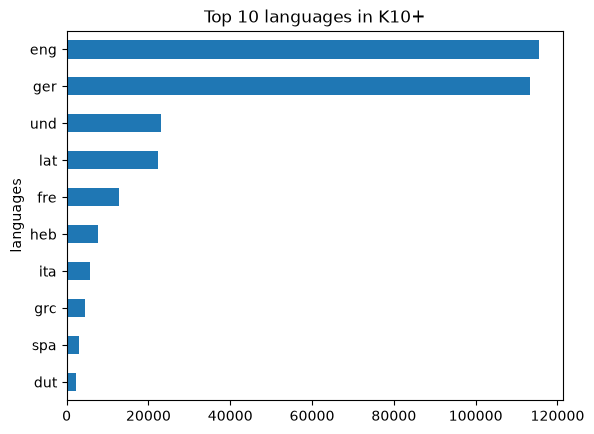

In [8]:
languages = books["languages"].explode().dropna().astype("string")
language_counts = languages.value_counts()
language_counts.head(10).sort_values().plot(
    kind="barh", title="Top 10 languages in K10+"
)

In [9]:
stop = {
    "eng": set(stopwords.words("english")),  # 198 words
    "ger": set(stopwords.words("german")),   # 232 words
    "fre": set(stopwords.words("french")),   # 157 words
}

In [11]:
language_spacy_map = {
    "eng": nlp_eng,
    "ger": nlp_ger,
    "fre": nlp_fra,
}

In [12]:
title = "This Is a Sample Book Title: Containing also a Subtitle"
def clean_title(title, languages=["eng", "ger", "fre"]):
    nlp = language_spacy_map.get(languages[0])
    if not nlp:
        return title
    doc = nlp(title)
    title = " ".join([token.lemma_ for token in doc if token.pos_ in ["NOUN", "PROPN", "ADJ", "VERB"]])
    title = title.lower()
    _trim = " \t.,;:!?()[]{}\"'«»“”‘’–—_-*/" # in case of not being processed...
    title = " ".join([tok for tok in (t.strip(_trim) for t in title.split()) if tok])
    return title
title_cleaned = clean_title(title)
title_cleaned

'sample book title contain subtitle'

In [13]:
books_21st = books[books["publication_year"] >= 2000].copy()
len(books_21st)

87797

In [14]:
# there is a language overlap between the "languages" list and the list ["eng", "ger", "fre"]
books_21st_enggerfre = books_21st[books_21st["languages"].apply(lambda langs: langs[0] in ["eng", "ger", "fre"])]
len(books_21st_enggerfre)

78341

In [17]:
books_21st_enggerfre["title_cleaned"] = books_21st_enggerfre.apply(
    lambda row: clean_title(row["full_title"], row["languages"]), axis=1
)

In [16]:
books_21st_enggerfre.to_parquet(DATA_DIR / "books_21st_enggerfre.parquet", index=False) # , compression="zstd")